# 01 — SMARD raw-data audit

**Question:** Are the supplied hourly and daily datasets complete and internally consistent?

This notebook parses values for inspection and leaves both source CSV files unchanged. It does not impute, remove outliers, or train a model. Structural checks cover 2019–2024; exploratory plots and outlier screening use **2019–2023** to preserve the 2024 evaluation period.

Run cells from top to bottom, locally or from this repository's Databricks Git folder. Required packages: pandas, numpy, matplotlib. Source: Bundesnetzagentur | SMARD.de. The bundled SMARD user guide, section B 1.4, specifies local CET/CEST timestamps and the repeated autumn hour.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from either the repository root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the electricity-reg-germany Git folder.')

TARGET = 'Netzlast [MWh] Berechnete Auflösungen'
TIMEZONE = 'Europe/Berlin'
VALUE_COLS = [TARGET,
    'Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen',
    'Pumpspeicher [MWh] Berechnete Auflösungen',
    'Residuallast [MWh] Berechnete Auflösungen']
FILES = {resolution: ROOT / 'data' /
         f'Realisierter_Stromverbrauch_201901010000_202501010000_{suffix}.csv'
         for resolution, suffix in [('hourly', 'Stunde'), ('daily', 'Tag')]}
raw = {name: pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str)
       for name, path in FILES.items()}
for name, frame in raw.items():
    print(f'{name}: {len(frame):,} rows × {len(frame.columns)} columns')
    display(frame.head(5))

Matplotlib is building the font cache; this may take a moment.


hourly: 52,608 rows × 6 columns


,Datum von,Datum bis,Netzlast [MWh] Berechnete Auflösungen,Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Residuallast [MWh] Berechnete Auflösungen
0,01.01.2019 00:00,01.01.2019 01:00,"43.273,75","44.546,75","1.273,00","19.825,50"
1,01.01.2019 01:00,01.01.2019 02:00,"41.631,25","43.042,00","1.410,75","16.465,75"
2,01.01.2019 02:00,01.01.2019 03:00,"40.085,00","42.561,75","2.476,75","14.456,25"


daily: 2,192 rows × 6 columns


,Datum von,Datum bis,Netzlast [MWh] Berechnete Auflösungen,Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Residuallast [MWh] Berechnete Auflösungen
0,01.01.2019,02.01.2019,"1.097.118,75","1.150.739,75","53.621,00","277.981,25"
1,02.01.2019,03.01.2019,"1.388.494,25","1.424.715,50","36.221,25","669.048,50"
2,03.01.2019,04.01.2019,"1.466.308,25","1.490.488,00","24.179,75","1.150.431,75"


## 1. Parse without cleaning

Preserve original strings in `raw`. Parse German decimal commas and thousands separators into separate inspection frames. Report blanks and nonnumeric tokens independently: a placeholder such as `-` is not a blank cell.

In [ ]:
parsed, numeric_checks = {}, []
for name, frame in raw.items():
    fmt = '%d.%m.%Y %H:%M' if name == 'hourly' else '%d.%m.%Y'
    df = pd.DataFrame({
        'start_local': pd.to_datetime(frame['Datum von'], format=fmt, errors='coerce'),
        'end_local': pd.to_datetime(frame['Datum bis'], format=fmt, errors='coerce'),
    })
    for col in VALUE_COLS:
        text = frame[col].str.strip()
        blank = text.isna() | text.eq('')
        number = pd.to_numeric(text.str.replace('.', '', regex=False)
                               .str.replace(',', '.', regex=False), errors='coerce')
        df[col] = number
        numeric_checks.append({'dataset': name, 'column': col,
            'blank': int(blank.sum()),
            'unparseable_nonblank': int((number.isna() & ~blank).sum()),
            'infinite': int(np.isinf(number).sum()),
            'negative': int(number.lt(0).sum()), 
            'zero': int(number.eq(0).sum())})
    parsed[name] = df
numeric_audit = pd.DataFrame(numeric_checks)
display(numeric_audit)
# Negative residual load can be meaningful; counts are observations, not deletion rules.

,dataset,column,blank,unparseable_nonblank,infinite,negative,zero
0,hourly,Netzlast [MWh] Berechnete Auflösungen,0,0,0,0,0
1,hourly,Netzlast inkl. Pumpspeicher [MWh] Berechnete A...,0,0,0,0,0
2,hourly,Pumpspeicher [MWh] Berechnete Auflösungen,0,0,0,0,113
3,hourly,Residuallast [MWh] Berechnete Auflösungen,0,0,0,126,0
4,daily,Netzlast [MWh] Berechnete Auflösungen,0,0,0,0,0
5,daily,Netzlast inkl. Pumpspeicher [MWh] Berechnete A...,0,0,0,0,0
6,daily,Pumpspeicher [MWh] Berechnete Auflösungen,0,0,0,0,0
7,daily,Residuallast [MWh] Berechnete Auflösungen,0,0,0,0,0


## 2. Time coverage and daylight saving

For hourly start times, `ambiguous="infer"` uses the original chronological row order to distinguish the two autumn hours. Failure is reported rather than silently shifting timestamps. This inference is an assumption to verify before implementing production preprocessing.

Hourly end labels in this export repeat `03:00` for both autumn `02:00` rows. Therefore we audit their raw labels separately and use **start times** for the UTC coverage check; we do not pretend every end label uniquely identifies a physical instant.

In [3]:
coverage_rows = []
for name, df in parsed.items():
    start = df['start_local']
    expected = pd.date_range('2019-01-01', '2025-01-01',
        freq='h' if name == 'hourly' else 'D', tz=TIMEZONE, inclusive='left')
    localization_error = None
    try:
        aware = pd.DatetimeIndex(start).tz_localize(
            TIMEZONE, ambiguous='infer', nonexistent='raise')
        utc = aware.tz_convert('UTC')
        df['start_utc'] = utc
        missing = len(expected.tz_convert('UTC').difference(utc))
        unexpected = len(utc.difference(expected.tz_convert('UTC')))
        duplicate_utc = int(utc.duplicated().sum())
    except Exception as exc:
        # Display the failure; do not repair it automatically.
        localization_error = str(exc)
        missing = unexpected = duplicate_utc = None
    coverage_rows.append({'dataset': name, 'rows': len(df),
        'expected_rows': len(expected), 'invalid_start': int(start.isna().sum()),
        'invalid_end': int(df['end_local'].isna().sum()),
        'duplicate_raw_rows': int(raw[name].duplicated().sum()),
        'repeated_local_starts': int(start.duplicated().sum()),
        'duplicate_utc_starts': duplicate_utc, 'missing_intervals': missing,
        'unexpected_intervals': unexpected,
        'ordered_local_starts': bool(start.is_monotonic_increasing),
        'timezone_error': localization_error})
coverage = pd.DataFrame(coverage_rows)
display(coverage)
hourly = parsed['hourly']
daily = parsed['daily']
print('Repeated local-hour rows (preserved):')
display(hourly.loc[hourly['start_local'].duplicated(keep=False),
                   ['start_local', 'end_local', TARGET]])
hours_per_day = hourly.groupby(hourly['start_local'].dt.normalize()).size()
print('Number of days by row count:')
display(hours_per_day.value_counts().sort_index().rename('days').to_frame())

,dataset,rows,expected_rows,invalid_start,invalid_end,duplicate_raw_rows,repeated_local_starts,duplicate_utc_starts,missing_intervals,unexpected_intervals,ordered_local_starts,timezone_error
0,hourly,52608,52608,0,0,0,6,0,0,0,True,None
1,daily,2192,2192,0,0,0,0,0,0,0,True,None


Repeated local-hour rows (preserved):


,start_local,end_local,Netzlast [MWh] Berechnete Auflösungen
7177,2019-10-27 02:00:00,2019-10-27 03:00:00,41796.00
7178,2019-10-27 02:00:00,2019-10-27 03:00:00,41113.00
15913,2020-10-25 02:00:00,2020-10-25 03:00:00,41656.75
15914,2020-10-25 02:00:00,2020-10-25 03:00:00,41052.25
24817,2021-10-31 02:00:00,2021-10-31 03:00:00,41807.25
24818,2021-10-31 02:00:00,2021-10-31 03:00:00,41221.25
33553,2022-10-30 02:00:00,2022-10-30 03:00:00,35357.00
33554,2022-10-30 02:00:00,2022-10-30 03:00:00,34717.00
42289,2023-10-29 02:00:00,2023-10-29 03:00:00,37379.25
42290,2023-10-29 02:00:00,2023-10-29 03:00:00,37440.50


Number of days by row count:


,days
23,6
24,2180
25,6


## 3. Compare hourly sums with the supplied daily data

Aggregate by **German local calendar date**, preserving 23/25-hour days. Require all hourly values to be present before calculating a day's sum. A 1 MWh tolerance below is a diagnostic threshold, not permission to overwrite either source.

In [4]:
hourly_sums = hourly.groupby(hourly['start_local'].dt.normalize())[VALUE_COLS].agg(
    lambda values: values.sum(min_count=len(values)))
daily_values = daily.set_index('start_local')[VALUE_COLS]
comparison = daily_values.join(hourly_sums, how='outer', lsuffix='_daily', rsuffix='_hourly')
consistency_rows = []
for col in VALUE_COLS:
    delta = comparison[f'{col}_daily'] - comparison[f'{col}_hourly']
    consistency_rows.append({'column': col, 'comparable_days': int(delta.notna().sum()),
        'noncomparable_days': int(delta.isna().sum()),
        'max_absolute_difference_MWh': float(delta.abs().max()),
        'days_above_1_MWh': int(delta.abs().gt(1).sum())})
consistency = pd.DataFrame(consistency_rows)
display(consistency)
target_delta = comparison[f'{TARGET}_daily'] - comparison[f'{TARGET}_hourly']
print('Largest daily/hourly target discrepancies:')
display(target_delta.loc[target_delta.abs().nlargest(5).index].rename('difference_MWh'))

/var/folders/8b/x8gv3fv51wd3tst2rqsk5mn80000gn/T/ipykernel_25079/2243208786.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  comparison = daily_values.join(hourly_sums, how='outer', lsuffix='_daily', rsuffix='_hourly')


,column,comparable_days,noncomparable_days,max_absolute_difference_MWh,days_above_1_MWh
0,Netzlast [MWh] Berechnete Auflösungen,2192,0,0.02,0
1,Netzlast inkl. Pumpspeicher [MWh] Berechnete A...,2192,0,0.02,0
2,Pumpspeicher [MWh] Berechnete Auflösungen,2192,0,0.00,0
3,Residuallast [MWh] Berechnete Auflösungen,2192,0,0.02,0


Largest daily/hourly target discrepancies:


start_local
2024-09-20   -0.02
2024-09-21   -0.01
2019-01-01    0.00
2019-01-02    0.00
2019-01-03    0.00
Name: difference_MWh, dtype: float64

## 4. Development-period distributions and unusual values

Only 2019–2023 is used here. The IQR rule marks observations for investigation, not errors: weekends, holidays and unusual economic conditions can produce legitimate extremes. It also ignores seasonality, so it is only an initial screen.

hourly: development-period numeric summary


,Netzlast [MWh] Berechnete Auflösungen,Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Residuallast [MWh] Berechnete Auflösungen
count,43824.000000,43824.000000,43824.000000,43824.000000
mean,55403.514878,56781.112330,1377.597452,35302.500391
std,9799.891164,9422.708961,1484.810071,13029.268592
min,30902.750000,31437.000000,0.000000,-5647.000000
25%,47461.437500,49405.500000,210.750000,26561.250000
50%,55222.750000,56690.375000,792.500000,35751.625000
75%,63173.625000,64117.812500,2165.000000,44318.250000
max,81319.500000,83453.750000,8102.000000,74638.750000


,start_local,Netzlast [MWh] Berechnete Auflösungen


daily: development-period numeric summary


,Netzlast [MWh] Berechnete Auflösungen,Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen,Pumpspeicher [MWh] Berechnete Auflösungen,Residuallast [MWh] Berechnete Auflösungen
count,1.826000e+03,1.826000e+03,1826.000000,1.826000e+03
mean,1.329684e+06,1.362747e+06,33062.338855,8.472600e+05
std,1.616720e+05,1.598403e+05,10450.454048,2.556783e+05
min,9.008570e+05,9.513478e+05,8523.250000,9.333450e+04
25%,1.224674e+06,1.257720e+06,25734.875000,6.721833e+05
50%,1.338672e+06,1.368001e+06,32257.750000,8.580672e+05
75%,1.445740e+06,1.476685e+06,39134.625000,1.033334e+06
max,1.681886e+06,1.723690e+06,70895.250000,1.568968e+06


,start_local,Netzlast [MWh] Berechnete Auflösungen


,dataset,development_rows,lower_IQR_bound_MWh,upper_IQR_bound_MWh,flagged_target_values
0,hourly,43824,23893.15625,8.674191e+04,0
1,daily,1826,893075.59375,1.777338e+06,0


/var/folders/8b/x8gv3fv51wd3tst2rqsk5mn80000gn/T/ipykernel_25079/1690020116.py:28: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d.groupby(d['start_local'].dt.dayofweek)[TARGET].mean().plot.bar(ax=axes[1, 1])


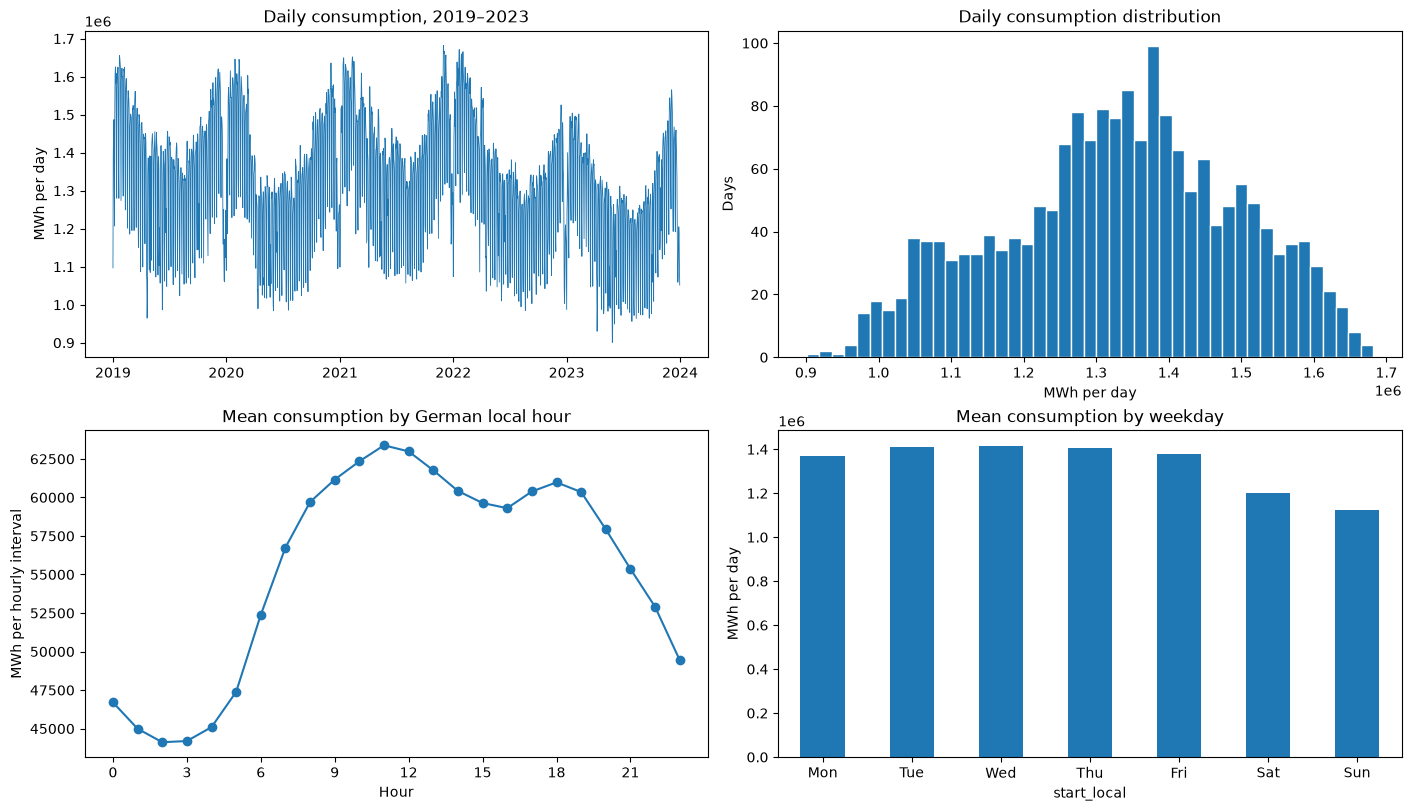

In [5]:
development = {name: df.loc[df['start_local'] < '2024-01-01'].copy()
               for name, df in parsed.items()}
outlier_rows = []
for name, df in development.items():
    values = df[TARGET]
    q1, q3 = values.quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = values.lt(lower) | values.gt(upper)
    outlier_rows.append({'dataset': name, 'development_rows': len(df),
        'lower_IQR_bound_MWh': lower, 'upper_IQR_bound_MWh': upper,
        'flagged_target_values': int(flagged.sum())})
    print(f'{name}: development-period numeric summary')
    display(df[VALUE_COLS].describe())
    display(df.loc[flagged, ['start_local', TARGET]].head(10))
outlier_audit = pd.DataFrame(outlier_rows)
display(outlier_audit)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
d = development['daily']
axes[0, 0].plot(d['start_local'], d[TARGET], linewidth=0.6)
axes[0, 0].set(title='Daily consumption, 2019–2023', ylabel='MWh per day')
axes[0, 1].hist(d[TARGET].dropna(), bins=45, edgecolor='white')
axes[0, 1].set(title='Daily consumption distribution', xlabel='MWh per day', ylabel='Days')
h = development['hourly']
h.groupby(h['start_local'].dt.hour)[TARGET].mean().plot(ax=axes[1, 0], marker='o')
axes[1, 0].set(title='Mean consumption by German local hour',
               xlabel='Hour', ylabel='MWh per hourly interval', xticks=range(0, 24, 3))
d.groupby(d['start_local'].dt.dayofweek)[TARGET].mean().plot.bar(ax=axes[1, 1])
axes[1, 1].set(title='Mean consumption by weekday', ylabel='MWh per day')
axes[1, 1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], rotation=0)
plt.show()

## 5. Record findings and choose the next step

The following cell prints a reproducible structural summary.

In [6]:
print('STRUCTURAL AUDIT SUMMARY')
print(coverage.to_string(index=False))
print(); print('NUMERIC CHECKS')
print(numeric_audit.to_string(index=False))
print(); print('DAILY / HOURLY CONSISTENCY')
print(consistency.to_string(index=False))
print(); print('DEVELOPMENT-PERIOD IQR SCREEN')
print(outlier_audit.to_string(index=False))

STRUCTURAL AUDIT SUMMARY
dataset  rows  expected_rows  invalid_start  invalid_end  duplicate_raw_rows  repeated_local_starts  duplicate_utc_starts  missing_intervals  unexpected_intervals  ordered_local_starts timezone_error
 hourly 52608          52608              0            0                   0                      6                     0                  0                     0                  True           None
  daily  2192           2192              0            0                   0                      0                     0                  0                     0                  True           None

NUMERIC CHECKS
dataset                                                   column  blank  unparseable_nonblank  infinite  negative  zero
 hourly                    Netzlast [MWh] Berechnete Auflösungen      0                     0         0         0     0
 hourly Netzlast inkl. Pumpspeicher [MWh] Berechnete Auflösungen      0                     0         0         0     0

- The repeated local starts occur at the autumn daylight-saving transition, once
per year. The SMARD guide (section B 1.4) specifies CET/CEST time. Preserving
source row order and localizing with `Europe/Berlin` and `ambiguous="infer"`
produces unique, continuous UTC hourly starts. This relies on chronological
source ordering and complete repeated-hour pairs; future loaders must validate
those conditions rather than assume inference will always succeed.

- Both repeated autumn `02:00` rows carry `03:00` as the raw end label. Those
labels do not uniquely specify physical interval boundaries. Coverage was
verified from start times; end timestamps were checked for parseability only.

- Summing the hourly target by German local date matches every supplied daily
target within **0.02 MWh**. All 2,192 days are comparable. The maximum absolute
differences for grid load including pumping, pumped-storage consumption and
residual load are respectively 0.02, 0.00 and 0.02 MWh. These small differences
are consistent with rounding; the audit does not establish their provenance.

- Additional observations: hourly residual load is negative in 126 intervals, and
hourly pumped-storage consumption is zero in 113 intervals. These concern
auxiliary variables, not the target, and are not automatically data errors.